# Everpure Phase 3 — illustrative Monte Carlo NPV

**Financial scenario simulation, not an empirically calibrated revenue forecast.** The 1,144-account provisional cohort has no observed reactivation outcomes, post-event revenue, margins, treatment effects, or incremental profits. All six figures are model conditional and use aggregate outputs only. The externally verified assessment brief requires 1,000 runs and three discount tiers but gives no offer percentages or unit economics; 5%, 15% and 30% are analyst-selected hypothetical offers.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from everpure_case.phase3_pipeline import _inputs, _scenario_hazards, validate_phase3_artifacts
from everpure_case.financial_model import account_expectation, discount_factor
out = ROOT / 'outputs/phase3'
fig_dir = out / 'figures'
fig_dir.mkdir(exist_ok=True)
contract, assumptions, detail, base = _inputs(ROOT)
validation = validate_phase3_artifacts(ROOT, mode='handoff')
summary = pd.read_csv(out / 'monte_carlo_npv_summary.csv')
runs = pd.read_csv(out / 'monte_carlo_run_results.csv')
monthly = pd.read_csv(out / 'monthly_cashflow_summary.csv')
sensitivity = pd.read_csv(out / 'financial_sensitivity.csv')
break_even = pd.read_csv(out / 'discount_break_even.csv')
reconciliation = json.loads((out / 'financial_reconciliation.json').read_text())
assert len(runs) == 9000 and len(summary) == 9 and len(base) == 1144
assert summary.standardized_discrepancy.abs().max() < reconciliation['z_limit']
pd.DataFrame([{'source_sha256': contract['source_sha256'], 'phase2_probability_sha256': contract['probability_artifact_sha256'], 'financial_assumption_fingerprint': assumptions['fingerprint_sha256'], 'provenance': assumptions['provenance']}])

,source_sha256,phase2_probability_sha256,financial_assumption_fingerprint,provenance
0,6863ea0014f050355bf9e0c5166e2284edfe8521ea3d87...,6322a0adc58dbaa999e5523f3a17db5faaa61ca3f8a359...,b953c02d3fdcfacc62d9e6755889040e9f8bd12db7c830...,ASSUMPTION_BASED_NOT_CALIBRATED


## Mechanics and assumptions

One independent uniform per account and replication is shared across hazard scenarios. For monthly assumed hazard $h_i$, first-event time is $T_i=-\log(1-U_i)/h_i$. The 5%, 15%, and 30% customer price discounts do not alter the hazard. A full month $m$ is billed only when $T_i\le m-1$; cash is collected at month end. Outreach is paid at month zero and activation at $T_i$ when $T_i\le12$. Contribution margin includes ongoing servicing costs. Retention through month 12 is assumed. Financial discounting uses the annual effective rate.

In [2]:
display(pd.DataFrame([{'monthly_gross_revenue_usd': assumptions['monthly_gross_revenue_per_reactivated_account'], 'contribution_margin': assumptions['contribution_margin'], 'outreach_per_target_usd': assumptions['outreach_cost_per_target'], 'activation_per_event_usd': assumptions['activation_cost_per_reactivation'], 'annual_financial_discount_rate': assumptions['annual_effective_financial_discount_rate'], 'commercial_discount_tiers': str(assumptions['commercial_discount_tiers']), 'simulations_per_cell': assumptions['simulations_per_cell'], 'seed': assumptions['seed']}]))
hazards = _scenario_hazards(detail, base, 'base')
oracle = account_expectation(hazards, assumptions, assumptions['commercial_discount_tiers']['medium_15pct'])
assert np.isclose(oracle.expected_account_npv.sum(), summary.query("reactivation_scenario == 'base' and commercial_discount_tier == 'medium_15pct'").analytic_expected_npv.iloc[0])
display(summary[['reactivation_scenario', 'commercial_discount_tier', 'mean_npv', 'analytic_expected_npv', 'mc_standard_error', 'standardized_discrepancy']].round(2))

,monthly_gross_revenue_usd,contribution_margin,outreach_per_target_usd,activation_per_event_usd,annual_financial_discount_rate,commercial_discount_tiers,simulations_per_cell,seed
0,1000.0,0.6,100.0,200.0,0.12,"{'high_30pct': 0.3, 'low_5pct': 0.05, 'medium_...",1000,20261009


,reactivation_scenario,commercial_discount_tier,mean_npv,analytic_expected_npv,mc_standard_error,standardized_discrepancy
0,conservative,low_5pct,68469.19,66866.14,850.59,1.88
1,conservative,medium_15pct,47890.09,46464.54,756.82,1.88
2,conservative,high_30pct,17021.43,15862.13,616.18,1.88
3,base,low_5pct,243113.10,241533.35,1152.34,1.37
4,base,medium_15pct,202912.47,201501.66,1025.46,1.38
5,base,high_30pct,142611.52,141454.13,835.18,1.39
6,optimistic,low_5pct,465794.18,464630.73,1403.34,0.83
7,optimistic,medium_15pct,400610.14,399568.03,1249.09,0.83
8,optimistic,high_30pct,302834.07,301973.98,1017.75,0.85


## Six aggregate figures

All money is USD for the 1,144-account provisional cohort.

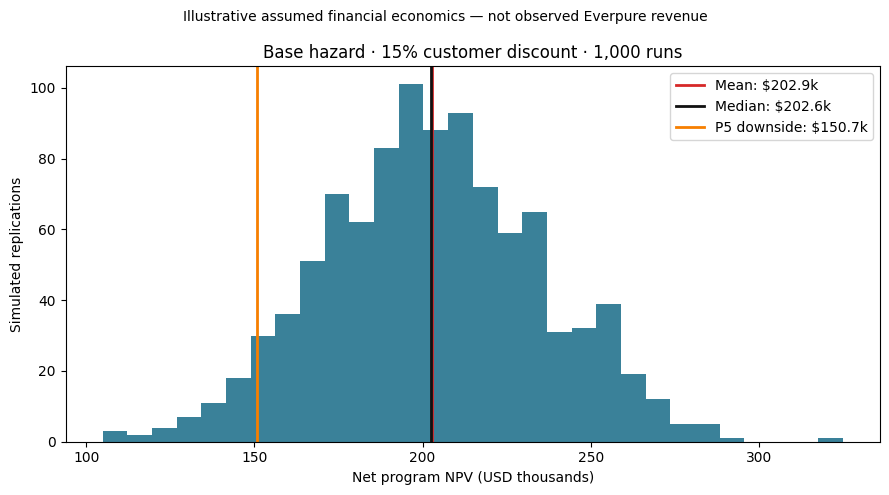

In [3]:
center = runs.query("reactivation_scenario == 'base' and commercial_discount_tier == 'medium_15pct'").npv
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(center / 1000, bins=30, color='#176b87', alpha=.85)
for val, label, color in [(center.mean(), 'Mean', '#d62828'), (center.median(), 'Median', '#111111'), (center.quantile(.05), 'P5 downside', '#f77f00')]:
    ax.axvline(val / 1000, color=color, linewidth=2, label=f'{label}: ${val/1000:,.1f}k')
ax.set(xlabel='Net program NPV (USD thousands)', ylabel='Simulated replications', title='Base hazard · 15% customer discount · 1,000 runs')
ax.legend()
fig.suptitle('Illustrative assumed financial economics — not observed Everpure revenue', fontsize=10)
fig.tight_layout(); fig.savefig(fig_dir / 'npv_distribution.png', dpi=150); display(fig); plt.close(fig)

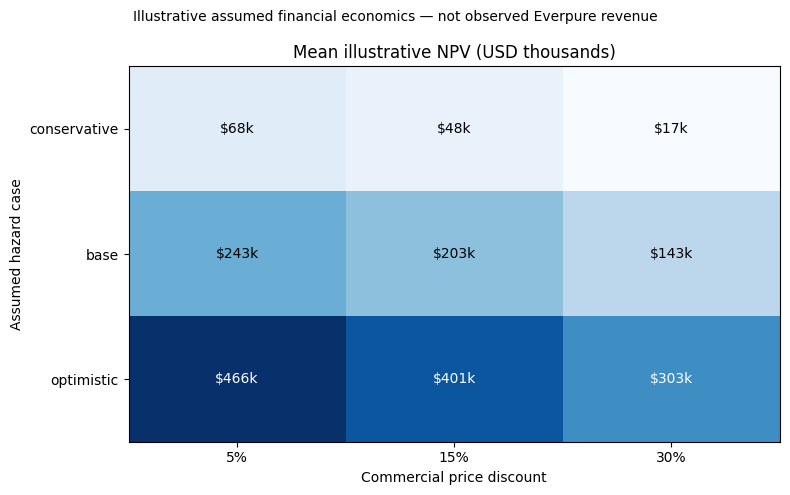

In [4]:
order = ['conservative', 'base', 'optimistic']
tiers = ['low_5pct', 'medium_15pct', 'high_30pct']
grid = summary.pivot(index='reactivation_scenario', columns='commercial_discount_tier', values='mean_npv').loc[order, tiers] / 1000
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(grid, cmap='Blues', aspect='auto')
for i in range(3):
    for j in range(3): ax.text(j, i, f'${grid.iloc[i,j]:,.0f}k', ha='center', va='center', color='white' if grid.iloc[i,j] > grid.to_numpy().max()*.6 else 'black')
ax.set(xticks=range(3), yticks=range(3), xticklabels=['5%', '15%', '30%'], yticklabels=order, xlabel='Commercial price discount', ylabel='Assumed hazard case', title='Mean illustrative NPV (USD thousands)')
fig.suptitle('Illustrative assumed financial economics — not observed Everpure revenue', fontsize=10)
fig.tight_layout(); fig.savefig(fig_dir / 'nine_cell_comparison.png', dpi=150); display(fig); plt.close(fig)

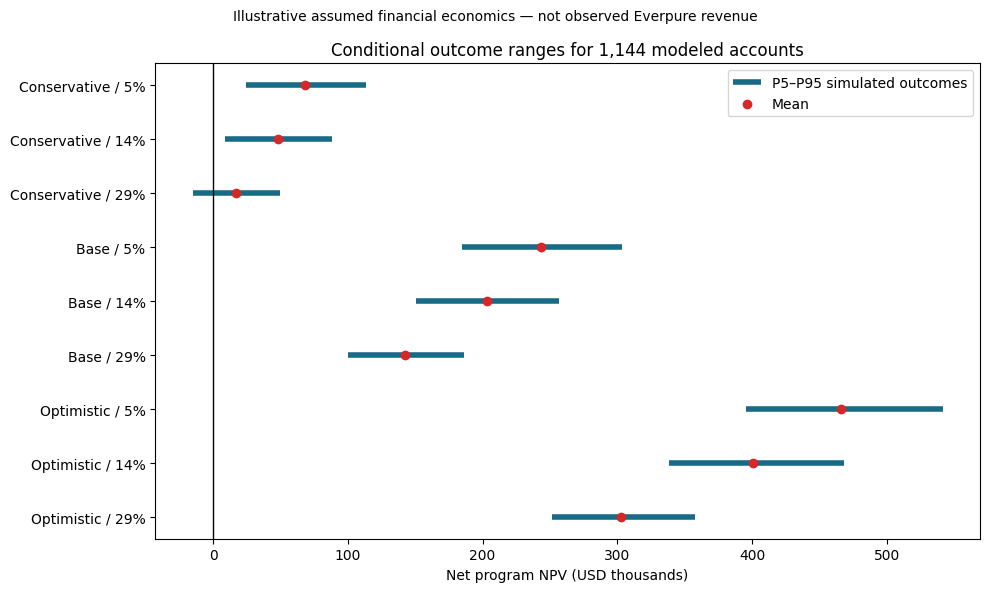

In [5]:
s = summary.copy()
s['scenario_order'] = pd.Categorical(s.reactivation_scenario, categories=['conservative','base','optimistic'], ordered=True)
s = s.sort_values(['scenario_order', 'commercial_discount_rate']).reset_index(drop=True)
labels = s.reactivation_scenario.str.title() + ' / ' + (100*s.commercial_discount_rate).astype(int).astype(str) + '%'
y = np.arange(len(s))
fig, ax = plt.subplots(figsize=(10, 6))
ax.hlines(y, s.p05_npv/1000, s.p95_npv/1000, color='#176b87', linewidth=4, label='P5–P95 simulated outcomes')
ax.scatter(s.mean_npv/1000, y, color='#d62828', zorder=3, label='Mean')
ax.axvline(0, color='black', linewidth=1); ax.set(yticks=y, yticklabels=labels, xlabel='Net program NPV (USD thousands)', title='Conditional outcome ranges for 1,144 modeled accounts')
ax.invert_yaxis(); ax.legend()
fig.suptitle('Illustrative assumed financial economics — not observed Everpure revenue', fontsize=10)
fig.tight_layout(); fig.savefig(fig_dir / 'npv_risk_ranges.png', dpi=150); display(fig); plt.close(fig)

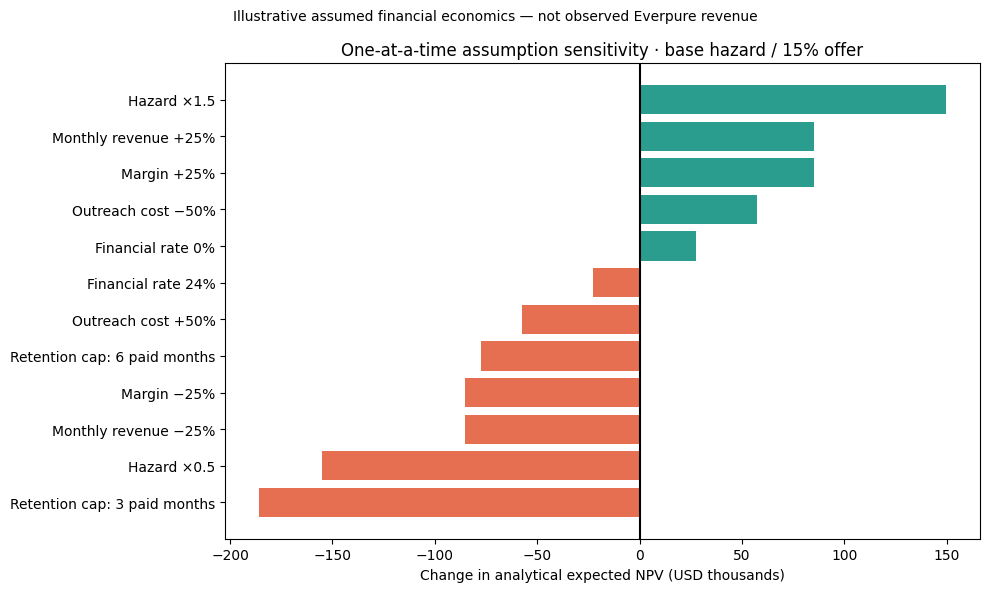

In [6]:
sel = sensitivity[sensitivity.changed_parameter.isin(['monthly_gross_revenue_per_reactivated_account', 'contribution_margin', 'outreach_cost_per_target', 'annual_effective_financial_discount_rate', 'hazard_multiplier', 'retention_paid_months']) & (sensitivity.sensitivity_case != 'baseline')].copy()
sel = sel.sort_values('difference_from_baseline')
plot_labels = {'hazard_1.5x':'Hazard ×1.5', 'hazard_0.5x':'Hazard ×0.5', 'monthly_gross_revenue_per_reactivated_account_1.25x':'Monthly revenue +25%', 'monthly_gross_revenue_per_reactivated_account_0.75x':'Monthly revenue −25%', 'contribution_margin_1.25x':'Margin +25%', 'contribution_margin_0.75x':'Margin −25%', 'outreach_cost_per_target_0.5x':'Outreach cost −50%', 'outreach_cost_per_target_1.5x':'Outreach cost +50%', 'financial_rate_0':'Financial rate 0%', 'financial_rate_0.24':'Financial rate 24%', 'retention_cap_3_paid_months':'Retention cap: 3 paid months', 'retention_cap_6_paid_months':'Retention cap: 6 paid months'}
sel['plot_label'] = sel.sensitivity_case.map(plot_labels)
assert sel.plot_label.notna().all()
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(sel.plot_label, sel.difference_from_baseline/1000, color=np.where(sel.difference_from_baseline>=0, '#2a9d8f', '#e76f51'))
ax.axvline(0, color='black'); ax.set(xlabel='Change in analytical expected NPV (USD thousands)', title='One-at-a-time assumption sensitivity · base hazard / 15% offer')
fig.suptitle('Illustrative assumed financial economics — not observed Everpure revenue', fontsize=10)
fig.tight_layout(); fig.savefig(fig_dir / 'financial_sensitivity.png', dpi=150); display(fig); plt.close(fig)

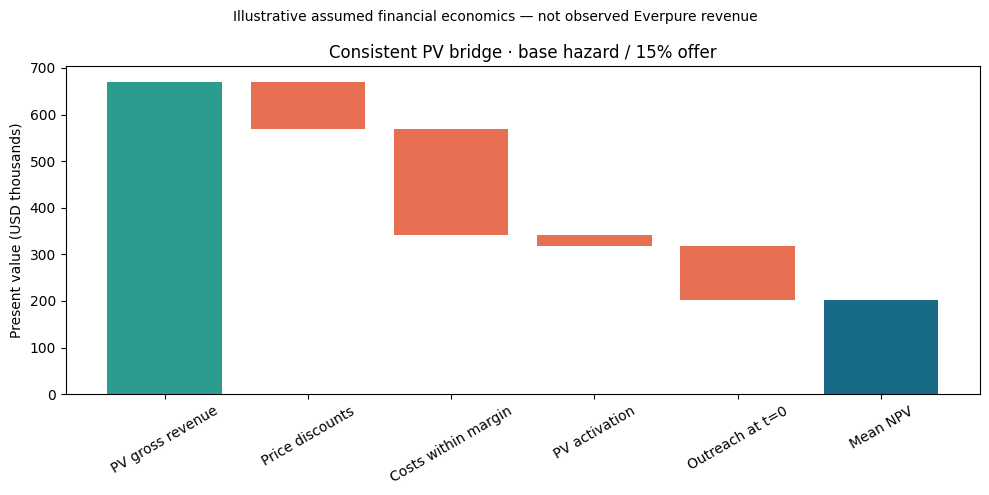

In [7]:
c = monthly.query("reactivation_scenario == 'base' and commercial_discount_tier == 'medium_15pct'").sort_values('month')
df = discount_factor(c.month.to_numpy(), assumptions['annual_effective_financial_discount_rate'])
pv_gross = float((c.mean_gross_revenue * df).sum())
pv_price_deduction = float((c.mean_commercial_discount_deduction * df).sum())
pv_discounted_revenue = pv_gross - pv_price_deduction
pv_margin_deduction = pv_discounted_revenue - float(c.mean_pv_contribution.sum())
pv_activation = float(c.mean_pv_activation_cost.sum())
outreach = float(c.mean_outreach_cost.sum())
bridge = [('PV gross revenue', pv_gross), ('Price discounts', -pv_price_deduction), ('Costs within margin', -pv_margin_deduction), ('PV activation', -pv_activation), ('Outreach at t=0', -outreach)]
assert np.isclose(sum(v for _,v in bridge), summary.query("reactivation_scenario == 'base' and commercial_discount_tier == 'medium_15pct'").mean_npv.iloc[0])
fig, ax = plt.subplots(figsize=(10, 5))
running = 0
for i,(name,value) in enumerate(bridge):
    ax.bar(i, abs(value)/1000, bottom=min(running, running+value)/1000, color='#2a9d8f' if value>=0 else '#e76f51')
    running += value
ax.bar(len(bridge), running/1000, color='#176b87')
ax.set(xticks=range(len(bridge)+1), xticklabels=[name for name,_ in bridge]+['Mean NPV'], ylabel='Present value (USD thousands)', title='Consistent PV bridge · base hazard / 15% offer')
ax.tick_params(axis='x', rotation=30)
fig.suptitle('Illustrative assumed financial economics — not observed Everpure revenue', fontsize=10)
fig.tight_layout(); fig.savefig(fig_dir / 'financial_pv_bridge.png', dpi=150); display(fig); plt.close(fig)

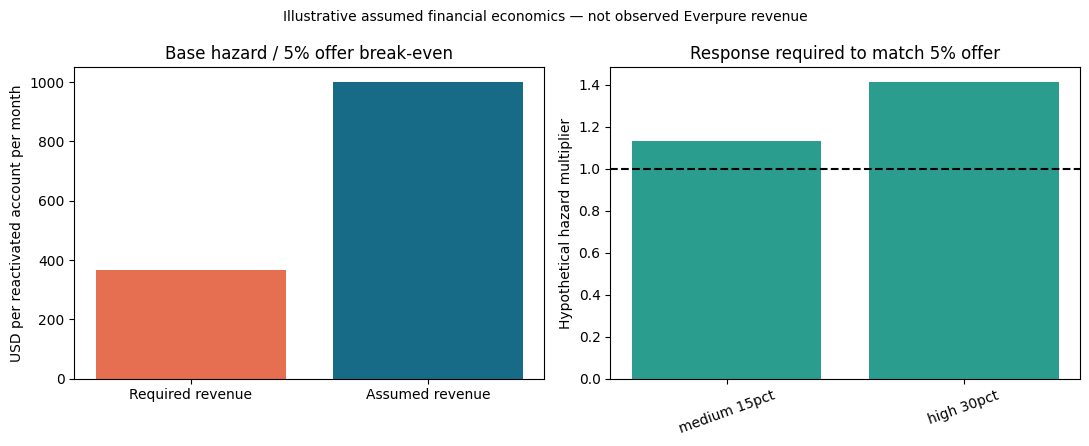

In [8]:
b = break_even.iloc[:4].copy()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(['Required revenue', 'Assumed revenue'], [b.loc[b.metric=='minimum_monthly_gross_revenue','threshold'].iloc[0], assumptions['monthly_gross_revenue_per_reactivated_account']], color=['#e76f51','#176b87'])
axes[0].set(ylabel='USD per reactivated account per month', title='Base hazard / 5% offer break-even')
d = break_even[break_even.metric=='discount_response_hazard_multiplier']
axes[1].bar(d.commercial_tier.str.replace('_',' '), d.threshold, color='#2a9d8f')
axes[1].axhline(1, color='black', linestyle='--'); axes[1].set(ylabel='Hypothetical hazard multiplier', title='Response required to match 5% offer')
axes[1].tick_params(axis='x', rotation=20)
fig.suptitle('Illustrative assumed financial economics — not observed Everpure revenue', fontsize=10)
fig.tight_layout(); fig.savefig(fig_dir / 'break_even_economics.png', dpi=150); display(fig); plt.close(fig)

## Limits and Phase 4 handoff

P5–P95 bars are simulated outcome quantiles, not confidence intervals for real value. The lowest discount mechanically yields the highest NPV because customer response is fixed across offers. The source spend period and parent-child consolidation rule are unknown, so historical spend never enters assumed monthly revenue. The Phase 4 contract identifies a confidential local account table and requires review or blocked states for unresolved eligibility, health, ownership, and quality. No routing is performed here.

In [9]:
phase4 = json.loads((out / 'phase4_input_contract.json').read_text())
display(pd.DataFrame([{'contract_version': phase4['version'], 'local_account_rows': phase4['local_account_input']['expected_rows'], 'classification': phase4['local_account_input']['classification'], 'forecast_months': phase4['forecast_horizon_months'], 'currency': phase4['currency']}]))

,contract_version,local_account_rows,classification,forecast_months,currency
0,phase3-to-phase4-v1,10296,CONFIDENTIAL_LOCAL_ONLY,12,USD
